# UAV Flight Power Consumption — Advanced SQL Analytics & Visualization

**Dataset:** `flights_ready_for_eda.csv` — 177,464 telemetry samples collected from **188 UAV flights**, each flight going through 3 operating regimes: `takeoff → cruise → landing`.

**Target variable:** `Power` (Watts, instantaneous power draw).

**Note on the time axis:** the dataset has no real timestamp column. Row order within each `flight` is used as a proxy for time progression (`sample_seq`), which is standard practice for high-frequency telemetry logs exported in acquisition order.

This notebook:
1. Runs a general exploratory overview of the raw data.
2. Executes 10 advanced SQL analyses (window functions, multi-level CTEs, conditional aggregation, Z-score, Pareto cumulative sums, rank shifting) using **DuckDB** directly on the pandas DataFrame.
3. Produces one meaningful visualization per analysis, each followed by a short data-driven insight.


## 0. Setup

In [ ]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110

import os
os.makedirs("figs", exist_ok=True)

df = pd.read_csv("../real_data/flights_ready_for_eda.csv")
df.columns = [c.lower() for c in df.columns]

# Proxy time-index: row order within each flight (acquisition sequence)
df["sample_seq"] = df.groupby("flight").cumcount()

con = duckdb.connect()
con.register("flight_telemetry", df)

print(df.shape)
df.head()


## Part 0 — General Exploratory Data Overview

In [ ]:
overview = con.execute('''
    SELECT
        COUNT(DISTINCT flight)                AS n_flights,
        COUNT(*)                              AS n_samples,
        COUNT(DISTINCT regime)                AS n_regimes,
        ROUND(AVG(power), 2)                  AS avg_power,
        ROUND(MIN(power), 2)                  AS min_power,
        ROUND(MAX(power), 2)                  AS max_power,
        ROUND(STDDEV(power), 2)               AS std_power
    FROM flight_telemetry
''').df()
overview


,n_flights,n_samples,n_regimes,avg_power,min_power,max_power,std_power
0,188,177464,3,523.81,3.34,1004.22,91.58


In [ ]:
regime_counts = con.execute('''
    SELECT regime, COUNT(*) AS n_samples, COUNT(DISTINCT flight) AS n_flights_using_regime
    FROM flight_telemetry GROUP BY regime ORDER BY n_samples DESC
''').df()
regime_counts


,regime,n_samples,n_flights_using_regime
0,cruise,95871,188
1,landing,50693,188
2,takeoff,30900,188


**0.0 Experimental design check**
`payload`, `speed` and `altitude` are mission **setpoints fixed once per flight**, not sensor readings that vary within a flight. Checking this matters because it decides how every later analysis should be read: e.g. "speed band" is really a per-flight setting, and payload (constant per flight) is the biggest single driver of power.

In [ ]:
const_check = con.execute('''
    SELECT MAX(n_payload) AS max_payload_values_per_flight,
           MAX(n_speed)   AS max_speed_values_per_flight,
           MAX(n_alt)     AS max_altitude_values_per_flight
    FROM (SELECT flight, COUNT(DISTINCT payload) n_payload, COUNT(DISTINCT speed) n_speed,
                 COUNT(DISTINCT altitude) n_alt
          FROM flight_telemetry GROUP BY flight)
''').df()
design = (con.execute('''
    SELECT payload, speed, COUNT(DISTINCT flight) AS n_flights
    FROM flight_telemetry GROUP BY payload, speed
''').df().pivot(index="payload", columns="speed", values="n_flights"))
print("Distinct setpoint values per flight (1 = constant within a flight):")
display(const_check)
print("Flights per payload x speed cell (balanced design):")
display(design)
print("Altitude setpoints:", sorted(df["altitude"].unique().tolist()))

Distinct setpoint values per flight (1 = constant within a flight):


,max_payload_values_per_flight,max_speed_values_per_flight,max_altitude_values_per_flight
0,1,1,1


Flights per payload x speed cell (balanced design):


speed,4.0,6.0,8.0,10.0,12.0
payload,,,,,
0.0,14,13,12,13,13
250.0,12,12,12,12,12
500.0,13,12,12,14,12


Altitude setpoints: [25, 50, 75, 100]


**Reading the design:** every flight uses exactly one payload (0 / 250 / 500), one speed (4 / 6 / 8 / 10 / 12 m/s) and one altitude (25 / 50 / 75 / 100), and each payload x speed cell holds 12-14 flights. Because the design is balanced, an average by speed is not distorted by payload, and vice versa.

**0.1 Power distribution — overall and by regime**
Understanding the shape of the target variable and how it differs across operating regimes.

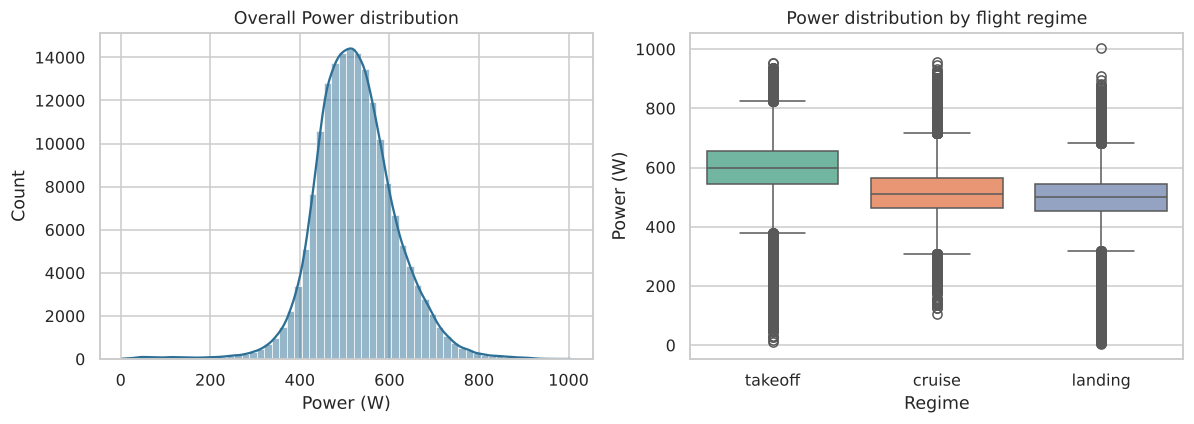

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df["power"], bins=60, kde=True, color="#2E6F95", ax=axes[0])
axes[0].set_title("Overall Power distribution")
axes[0].set_xlabel("Power (W)")

order = ["takeoff", "cruise", "landing"]
sns.boxplot(data=df, x="regime", y="power", order=order, hue="regime", hue_order=order, palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Power distribution by flight regime")
axes[1].set_xlabel("Regime")
axes[1].set_ylabel("Power (W)")

plt.tight_layout()
fig.savefig("figs/fig_eda_power_dist.pdf")
plt.show()


**0.2 Correlation heatmap of numeric features**
Quick check on which sensor readings move together with `Power`, and which are redundant with each other (useful before any modeling step).

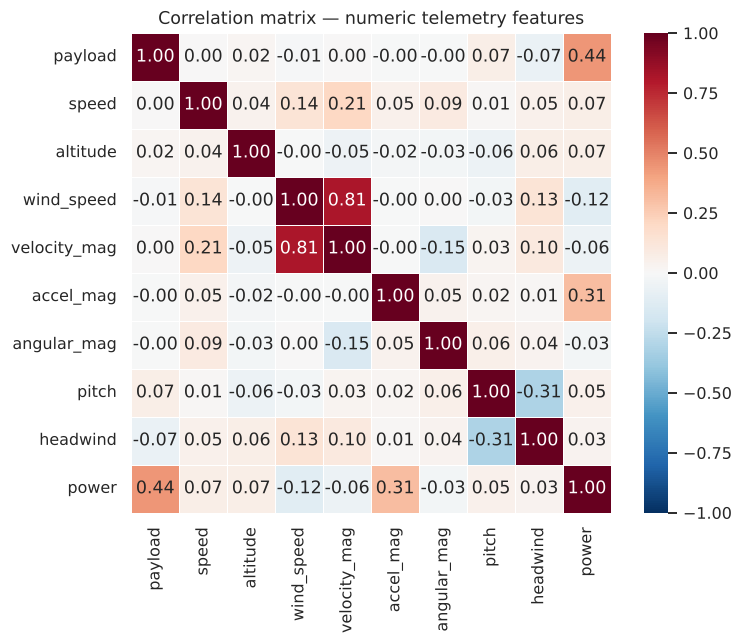

In [ ]:
num_cols = ["payload","speed","altitude","wind_speed","velocity_mag",
            "accel_mag","angular_mag","pitch","headwind","power"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.4, ax=ax)
ax.set_title("Correlation matrix — numeric telemetry features")
plt.tight_layout()
fig.savefig("figs/fig_eda_corr_heatmap.pdf")
fig.savefig("figs/fig_eda_corr_heatmap.png", dpi=200)
plt.show()


**0.3 Payload vs Power, colored by regime**
Payload only takes 3 discrete levels (0, 250, 500) in this dataset — a first look at how much it drives power draw, and whether that effect differs by regime.

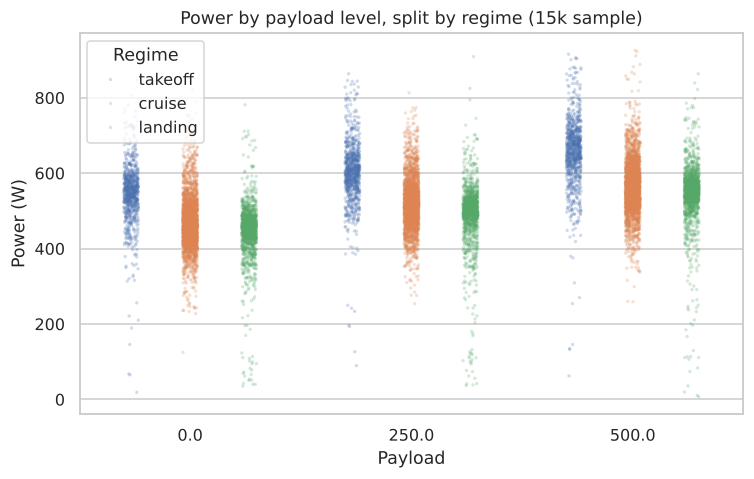

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.stripplot(data=df.sample(15000, random_state=42), x="payload", y="power",
              hue="regime", hue_order=order, dodge=True, alpha=0.25, size=2.2, ax=ax)
ax.set_title("Power by payload level, split by regime (15k sample)")
ax.set_xlabel("Payload"); ax.set_ylabel("Power (W)")
ax.legend(title="Regime", loc="upper left")
plt.tight_layout()
fig.savefig("figs/fig_eda_payload_power.pdf")
plt.show()


**0.4 Speed vs Power, colored by regime**
Speed is the operator-controlled variable most directly tied to energy cost — this scatter shows the relationship shape per regime.

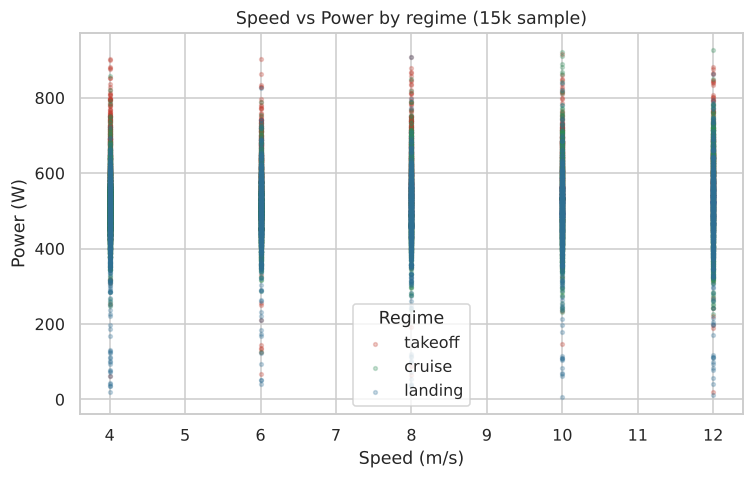

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sample = df.sample(15000, random_state=42)
for reg, c in zip(order, ["#C0392B", "#2E8B57", "#2E6F95"]):
    sub = sample[sample.regime == reg]
    ax.scatter(sub["speed"], sub["power"], s=6, alpha=0.25, color=c, label=reg)
ax.set_xlabel("Speed (m/s)"); ax.set_ylabel("Power (W)")
ax.set_title("Speed vs Power by regime (15k sample)")
ax.legend(title="Regime")
plt.tight_layout()
fig.savefig("figs/fig_eda_speed_power.pdf")
plt.show()


## Part 1 — Research Questions

- **RQ1 — Trend & Cycles:** How does power draw evolve over the course of a flight and across the three operating regimes? Are there recurring patterns tied to specific speed/altitude conditions?
- **RQ2 — Behavioral Segmentation:** Can the 188 flights be segmented by energy-consumption profile (level, volatility, payload) to support fleet maintenance/operations planning? Does energy efficiency hold steady from one regime to the next?
- **RQ3 — Contribution & Optimization:** Which flights / regimes / environmental conditions contribute disproportionately to total fleet energy consumption (Pareto), and is a flight's "most power-hungry" rank stable across regimes?
- **RQ4 — Anomaly Detection:** Are there statistically abnormal power readings relative to flight conditions (payload, speed, wind), and where do they concentrate? How does the share of "safe-band" samples change across the takeoff → cruise → landing journey?

## Part 2 — 10 Advanced SQL Analyses


### Analysis 1 — Power Along Flight Progress (LAG + progress bins)
**Serves:** RQ1
**Objective:** Show how power evolves *within* each regime. Regimes last a different number of samples in every flight, so the x-axis is **progress through the regime (0-100%)** rather than the raw sample index. A raw index averages over a shrinking set of long flights at the tail and hides the true shape. `LAG` gives the sample-to-sample change; `ROW_NUMBER` / `COUNT` window functions give the progress position.

In [ ]:
q1 = con.execute('''
    WITH ordered AS (
        SELECT flight, regime, power,
               LAG(power) OVER (PARTITION BY flight, regime ORDER BY sample_seq)            AS prev_power,
               ROW_NUMBER() OVER (PARTITION BY flight, regime ORDER BY sample_seq) - 1       AS rn,
               COUNT(*) OVER (PARTITION BY flight, regime)                                   AS n_in_regime
        FROM flight_telemetry
    ),
    binned AS (
        SELECT flight, regime, power, power - prev_power AS delta_power,
               CAST(FLOOR(50.0 * rn / n_in_regime) AS INTEGER) * 2 AS progress_pct   -- 2% bins
        FROM ordered
    )
    SELECT regime, progress_pct,
           AVG(power)       AS avg_power,
           AVG(delta_power) AS avg_delta_power,
           COUNT(DISTINCT flight) AS n_flights
    FROM binned
    GROUP BY regime, progress_pct
    ORDER BY regime, progress_pct
''').df()

summary1 = (q1.groupby("regime", sort=False)
              .agg(first_bin_W=("avg_power", "first"), peak_W=("avg_power", "max"),
                   lowest_W=("avg_power", "min"), last_bin_W=("avg_power", "last"),
                   min_flights_per_bin=("n_flights", "min"))
              .round(0).loc[order])
summary1["mid_phase_W (20-80% of regime)"] = (q1[q1.progress_pct.between(20, 80)].groupby("regime").avg_power.mean().round(0))
display(summary1)

# Is the end-of-landing drop real across flights, or driven by a few long flights?
landing_end = con.execute('''
    WITH r AS (
        SELECT flight, power,
               ROW_NUMBER() OVER (PARTITION BY flight ORDER BY sample_seq) - 1 AS rn,
               COUNT(*) OVER (PARTITION BY flight) AS n
        FROM flight_telemetry WHERE regime = 'landing'
    ),
    f AS (
        SELECT flight,
               AVG(CASE WHEN rn >= 0.96 * n THEN power END) AS last4,
               AVG(CASE WHEN rn <  0.96 * n THEN power END) AS rest
        FROM r GROUP BY flight
    )
    SELECT COUNT(*) AS n_flights,
           ROUND(100.0 * AVG(CASE WHEN last4 < rest THEN 1 ELSE 0 END), 1) AS pct_flights_lower_in_last_4pct,
           ROUND(MEDIAN(last4 - rest), 0) AS median_change_W
    FROM f
''').df()
print("Landing: last 4% of the phase vs the rest of the phase, per flight:")
display(landing_end)

,first_bin_W,peak_W,lowest_W,last_bin_W,min_flights_per_bin,mid_phase_W (20-80% of regime)
regime,,,,,,
takeoff,576.0,723.0,512.0,520.0,188,606.0
cruise,530.0,548.0,491.0,491.0,188,515.0
landing,463.0,518.0,229.0,229.0,188,505.0


Landing: last 4% of the phase vs the rest of the phase, per flight:


,n_flights,pct_flights_lower_in_last_4pct,median_change_W
0,188,94.1,-194.0


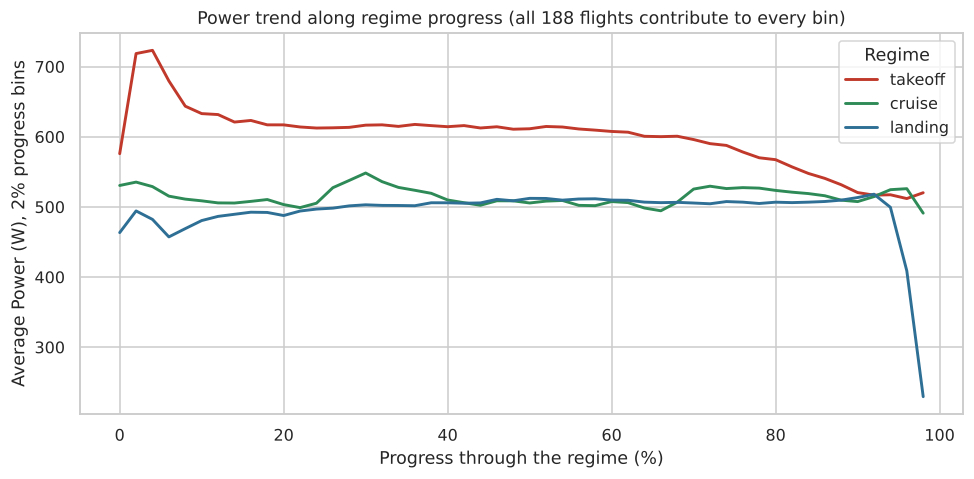

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for reg, c in zip(order, ["#C0392B", "#2E8B57", "#2E6F95"]):
    sub = q1[q1.regime == reg].sort_values("progress_pct")
    ax.plot(sub["progress_pct"], sub["avg_power"], color=c, lw=1.9, label=reg)
ax.set_xlabel("Progress through the regime (%)")
ax.set_ylabel("Average Power (W), 2% progress bins")
ax.set_title("Power trend along regime progress (all 188 flights contribute to every bin)")
ax.legend(title="Regime")
plt.tight_layout()
fig.savefig("figs/fig_a1_trend.pdf")
plt.show()

**Insight:** On a common 0-100% progress scale (every bin averages all 188 flights), the three regimes have distinct shapes. Takeoff starts at 576 W, spikes to a peak of 723 W within the first few percent of the phase, settles near 606 W (mean of the 20-80% bins) and eases to 520 W at the end. Cruise is the flattest: it stays between 491 W and 548 W (mid-phase mean 515 W). Landing climbs from 463 W to a plateau around 505 W and then collapses at the very end, to 229 W in the final 2% bin. The last 4% of the landing phase is lower than the rest of the phase in 94.1% of flights (median change -194 W), so this is a consistent end-of-flight effect, not an artefact of a few long flights. Regime, not elapsed time, sets the shape of the power curve.

### Analysis 2 — Regime x Speed Setpoint
**Serves:** RQ1
**Objective:** Find which regime / speed combinations draw more power. `speed` is a per-flight setpoint with 5 values (4, 6, 8, 10, 12 m/s), so it is used as-is rather than merged into bands (merging 10 and 12 m/s hides where the effect actually is). The payload effect is shown next to it for scale.

In [ ]:
q2 = con.execute('''
    SELECT regime, speed,
           COUNT(*) AS n_samples, COUNT(DISTINCT flight) AS n_flights,
           ROUND(AVG(power), 1) AS avg_power
    FROM flight_telemetry
    GROUP BY regime, speed
    ORDER BY regime, speed
''').df()

pivot = q2.pivot(index="regime", columns="speed", values="avg_power").reindex(order)
delta = pivot.sub(pivot.iloc[:, 0], axis=0)          # change vs the 4 m/s flights of the same regime
pivot.columns = delta.columns = [f"{int(s)} m/s" for s in pivot.columns]

q2b = (con.execute('''
    SELECT regime, payload, ROUND(AVG(power), 1) AS avg_power
    FROM flight_telemetry GROUP BY regime, payload
''').df().pivot(index="regime", columns="payload", values="avg_power").reindex(order))
q2b["payload_0_to_500_delta_W"] = (q2b[500.0] - q2b[0.0]).round(1)

print("Average power (W) by regime x speed setpoint:"); display(pivot)
print("Change vs 4 m/s (W):"); display(delta)
print("Average power (W) by regime x payload, for scale:"); display(q2b)

Average power (W) by regime x speed setpoint:


,4 m/s,6 m/s,8 m/s,10 m/s,12 m/s
regime,,,,,
takeoff,602.0,598.6,603.2,601.4,597.3
cruise,508.9,510.1,511.9,517.0,538.3
landing,489.2,494.3,493.3,497.1,494.7


Change vs 4 m/s (W):


,4 m/s,6 m/s,8 m/s,10 m/s,12 m/s
regime,,,,,
takeoff,0.0,-3.4,1.2,-0.6,-4.7
cruise,0.0,1.2,3.0,8.1,29.4
landing,0.0,5.1,4.1,7.9,5.5


Average power (W) by regime x payload, for scale:


payload,0.0,250.0,500.0,payload_0_to_500_delta_W
regime,,,,
takeoff,547.7,602.1,654.4,106.7
cruise,467.8,516.4,563.3,95.5
landing,443.9,493.4,544.2,100.3


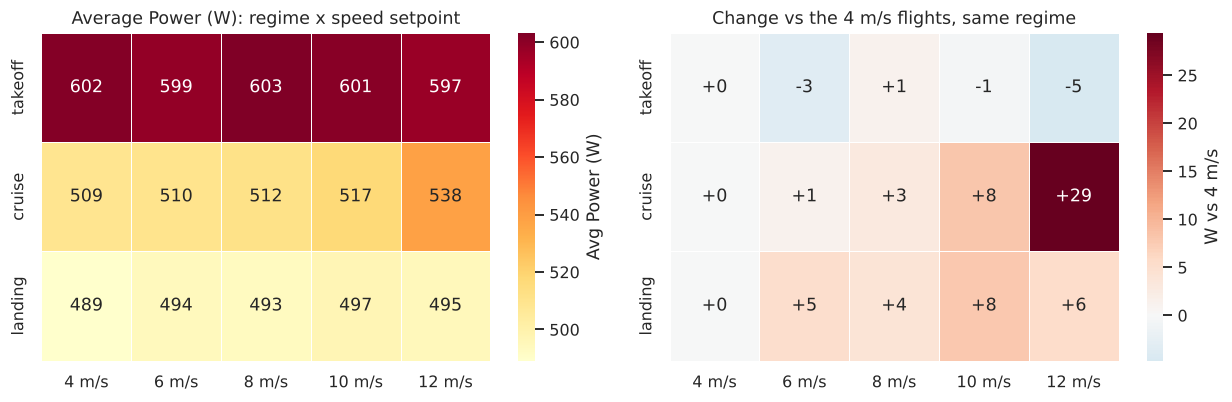

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.6, ax=axes[0],
            cbar_kws={"label": "Avg Power (W)"})
axes[0].set_title("Average Power (W): regime x speed setpoint"); axes[0].set_ylabel("")
sns.heatmap(delta, annot=True, fmt="+.0f", cmap="RdBu_r", center=0, linewidths=0.6, ax=axes[1],
            cbar_kws={"label": "W vs 4 m/s"})
axes[1].set_title("Change vs the 4 m/s flights, same regime"); axes[1].set_ylabel("")
plt.tight_layout()
fig.savefig("figs/fig_a2_heatmap.pdf")
plt.show()

**Insight:** Speed barely changes power in takeoff (597-603 W, no trend) or landing (489-497 W). Only cruise responds, and almost all of that happens at the top setpoint: +8 W at 10 m/s but +29 W at 12 m/s versus 4 m/s (509 W to 538 W, about +6%). Payload dominates by comparison: going from 0 to 500 adds 96-107 W in every regime. Each payload x speed cell holds 12-14 flights, so these averages are not distorted by payload. The speed "hot zone" is therefore cruise at 12 m/s; elsewhere the speed setting is a weak lever on power.

### Analysis 3 — Regime Duration & Transition Gap (Time-to-Event)
**Serves:** RQ1 (and feeds RQ3)
**Objective:** Measure how long (in samples, as a duration proxy) each regime lasts per flight, and the transition gap into the next regime.

In [ ]:
q3 = con.execute('''
    WITH regime_bounds AS (
        SELECT
            flight, regime,
            MIN(sample_seq) AS start_seq,
            MAX(sample_seq) AS end_seq,
            COUNT(*)         AS duration_samples,
            SUM(power)       AS energy_proxy
        FROM flight_telemetry
        GROUP BY flight, regime
    )
    SELECT flight, regime, start_seq, end_seq, duration_samples, energy_proxy
    FROM regime_bounds
''').df()
q3.groupby("regime")[["duration_samples", "energy_proxy"]].describe().round(1)


duration_samples                                                   \
                   count   mean    std    min    25%    50%    75%    max   
regime                                                                      
cruise             188.0  510.0  160.3  297.0  388.8  451.0  571.5  882.0   
landing            188.0  269.6   73.2  146.0  224.2  270.5  336.2  412.0   
takeoff            188.0  164.4   64.7   58.0  109.8  158.5  224.5  315.0   

        energy_proxy                                                   \
               count      mean      std       min       25%       50%   
regime                                                                  
cruise         188.0  262631.8  82207.8  147972.8  199915.0  233469.1   
landing        188.0  133128.1  38946.5   64256.7  101387.1  134446.8   
takeoff        188.0   98695.9  40888.2   32969.7   58773.0   94531.4   

                             
              75%       max  
regime                       
cruise   310601.5  461339.6  
landing  157355.8  227035.6  
takeoff  130149.9  198461.4

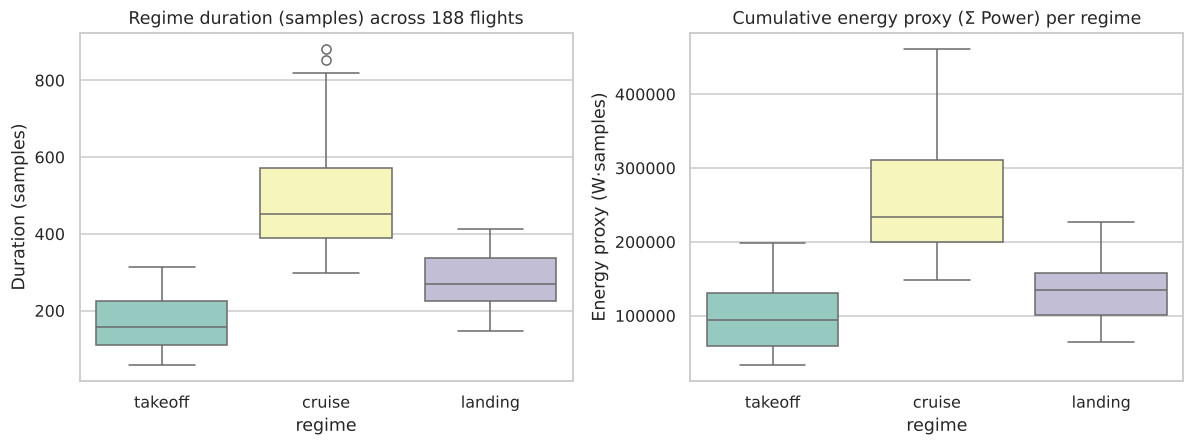

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.boxplot(data=q3, x="regime", y="duration_samples", order=order, hue="regime", hue_order=order, palette="Set3", legend=False, ax=axes[0])
axes[0].set_title("Regime duration (samples) across 188 flights")
axes[0].set_ylabel("Duration (samples)")

sns.boxplot(data=q3, x="regime", y="energy_proxy", order=order, hue="regime", hue_order=order, palette="Set3", legend=False, ax=axes[1])
axes[1].set_title("Cumulative energy proxy (Σ Power) per regime")
axes[1].set_ylabel("Energy proxy (W·samples)")

plt.tight_layout()
fig.savefig("figs/fig_a3_duration_energy.pdf")
fig.savefig("figs/fig_a3_duration_energy.png", dpi=200)
plt.show()


**Insight:** Cruise lasts about twice as long as landing and three times as long as takeoff (mean 510 vs 270 vs 164 samples). Even though its average power is lower than takeoff's, it accumulates by far the largest energy proxy (mean 262.6K vs 133.1K for landing and 98.7K for takeoff, in W-samples). Efficiency gains in cruise therefore compound more than gains in takeoff.

### Analysis 4 — Flight Segmentation by Energy Profile (RFM-style, NTILE)
**Serves:** RQ2
**Objective:** Segment the 188 flights along 3 axes analogous to RFM: average **Payload** (P), **Power volatility** (V, std of power) and **average Power** (M). The query also carries each flight's speed setpoint and mean wind so the segments can be explained afterwards. `payload` is fixed per flight, so the segments are expected to track it; the useful question is what separates flights *within* the same payload.

In [ ]:
q4 = con.execute('''
    WITH flight_agg AS (
        SELECT flight,
               AVG(payload)     AS avg_payload,
               ANY_VALUE(speed) AS speed,
               AVG(wind_speed)  AS avg_wind,
               STDDEV(power)    AS power_volatility,
               AVG(power)       AS avg_power
        FROM flight_telemetry
        GROUP BY flight
    ),
    scored AS (
        SELECT *,
               NTILE(4) OVER (ORDER BY avg_payload)      AS p_tile,
               NTILE(4) OVER (ORDER BY power_volatility) AS v_tile,
               NTILE(4) OVER (ORDER BY avg_power)        AS m_tile
        FROM flight_agg
    )
    SELECT *,
        CASE
            WHEN m_tile = 4 AND v_tile = 4  THEN 'High-power & unstable'
            WHEN m_tile = 4 AND v_tile <= 2 THEN 'High-power but stable'
            WHEN m_tile = 1 AND v_tile = 1  THEN 'Low-power & stable (benchmark)'
            ELSE 'Average'
        END AS segment_label
    FROM scored
''').df()

seg_summary = (q4.groupby("segment_label")
                 .agg(n_flights=("flight", "size"), avg_payload=("avg_payload", "mean"),
                      avg_power_W=("avg_power", "mean"), volatility_W=("power_volatility", "mean"),
                      avg_speed=("speed", "mean"), avg_wind=("avg_wind", "mean"))
                 .round(1))
vol_corr = (q4[["power_volatility", "avg_power", "avg_payload", "avg_wind", "speed"]]
              .corr(method="spearman").loc["power_volatility"].drop("power_volatility").round(2))
print("Segment profile:"); display(seg_summary)
print("Spearman correlation of a flight's power volatility with ...:"); display(vol_corr.to_frame("rho"))

Segment profile:


,n_flights,avg_payload,avg_power_W,volatility_W,avg_speed,avg_wind
segment_label,,,,,,
Average,139,219.4,518.2,81.7,8.2,5.7
High-power & unstable,17,500.0,582.1,98.7,9.9,6.2
High-power but stable,15,500.0,577.0,71.3,6.0,5.0
Low-power & stable (benchmark),17,0.0,465.8,58.1,5.6,4.8


Spearman correlation of a flight's power volatility with ...:


,rho
avg_power,0.28
avg_payload,0.13
avg_wind,0.76
speed,0.63


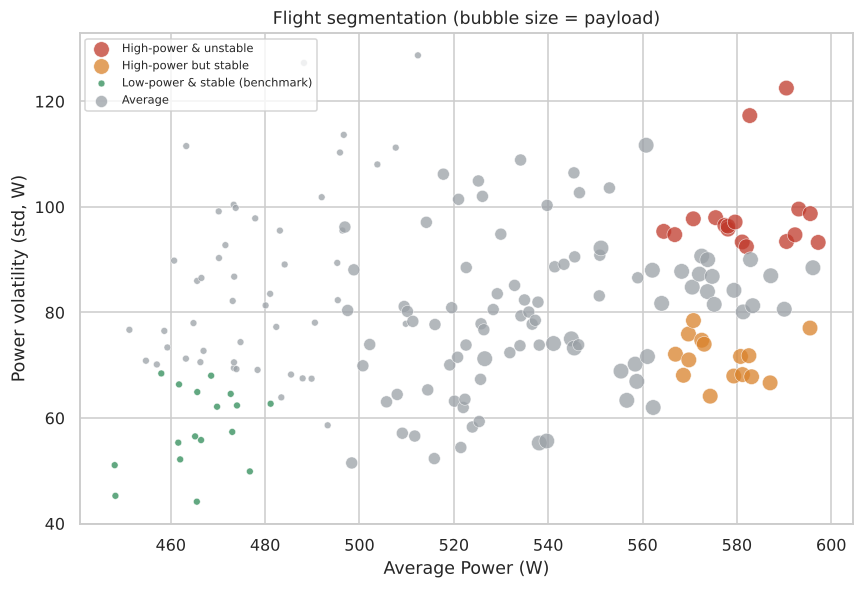

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
palette = {"High-power & unstable": "#C0392B", "High-power but stable": "#D9822B",
           "Low-power & stable (benchmark)": "#2E8B57", "Average": "#9AA0A6"}
for seg, c in palette.items():
    sub = q4[q4.segment_label == seg]
    ax.scatter(sub["avg_power"], sub["power_volatility"], s=sub["avg_payload"]/6 + 20,
               color=c, alpha=0.75, label=seg, edgecolor="white", linewidth=0.4)
ax.set_xlabel("Average Power (W)")
ax.set_ylabel("Power volatility (std, W)")
ax.set_title("Flight segmentation (bubble size = payload)")
ax.legend(fontsize=7.5, loc="upper left")
plt.tight_layout()
fig.savefig("figs/fig_a4_segmentation.pdf")
fig.savefig("figs/fig_a4_segmentation.png", dpi=200)
plt.show()

**Insight:** The segments track payload almost perfectly: all 17 low-power flights carry no payload and all 32 high-power flights carry the maximum (500). Payload sets the *level* of consumption, and the "benchmark" segment is simply the no-payload flights rather than a more efficient design. Volatility is a separate story. Among the high-power flights, the unstable ones fly faster (9.9 vs 6.0 m/s on average) and in stronger wind (6.2 vs 5.0). Across all 188 flights, power volatility correlates with mean wind speed (Spearman 0.76) and the speed setpoint (0.63) but only weakly with payload (0.13). Payload drives how much power a flight uses; wind and speed drive how erratic it is.

### Analysis 5 — Power Retention vs Takeoff Baseline (Cohort Analysis)
**Serves:** RQ2
**Objective:** Group flights into payload cohorts (0 / 250 / 500) and track each flight's average power in cruise and landing as a % of **its own takeoff average**, mirroring a cohort-retention grid.

*Why not `Power / velocity` (specific power)?* A first version used it, but near-hover samples make that ratio unstable: the check below shows how many samples have velocity under 1 m/s. The per-flight power ratio has no such problem.

In [ ]:
slow = con.execute('''
    SELECT regime,
           ROUND(100.0 * AVG(CASE WHEN velocity_mag < 1 THEN 1 ELSE 0 END), 1) AS pct_samples_below_1_mps
    FROM flight_telemetry GROUP BY regime
''').df().set_index("regime").loc[order]
print("Share of samples with velocity < 1 m/s (why Power/velocity is unstable):"); display(slow)

q5 = con.execute('''
    WITH regime_power AS (
        SELECT flight, payload AS payload_cohort, regime, AVG(power) AS avg_power
        FROM flight_telemetry GROUP BY flight, payload, regime
    ),
    with_base AS (
        SELECT *, MAX(CASE WHEN regime = 'takeoff' THEN avg_power END)
                      OVER (PARTITION BY flight) AS takeoff_power
        FROM regime_power
    )
    SELECT payload_cohort, regime,
           COUNT(*)                                                AS n_flights,
           ROUND(AVG(avg_power), 1)                                AS avg_power_W,
           ROUND(100.0 * AVG(avg_power / takeoff_power), 1)        AS retention_pct_vs_takeoff,
           ROUND(100.0 * STDDEV(avg_power / takeoff_power), 1)     AS sd_pct
    FROM with_base
    GROUP BY payload_cohort, regime
    ORDER BY payload_cohort, regime
''').df()
q5

Share of samples with velocity < 1 m/s (why Power/velocity is unstable):


,pct_samples_below_1_mps
regime,
takeoff,10.6
cruise,7.3
landing,21.8


,payload_cohort,regime,n_flights,avg_power_W,retention_pct_vs_takeoff,sd_pct
0,0.0,cruise,65,470.2,86.2,4.3
1,0.0,landing,65,444.1,81.5,4.7
2,0.0,takeoff,65,545.9,100.0,0.0
3,250.0,cruise,60,518.7,86.7,3.5
4,250.0,landing,60,493.5,82.5,4.2
5,250.0,takeoff,60,599.1,100.0,0.0
6,500.0,cruise,63,564.5,87.0,3.2
7,500.0,landing,63,543.2,83.7,3.5
8,500.0,takeoff,63,649.6,100.0,0.0


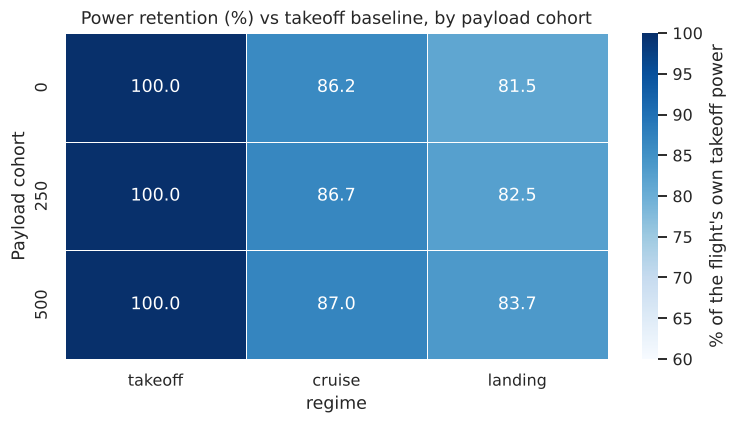

In [ ]:
pivot5 = q5.pivot(index="payload_cohort", columns="regime", values="retention_pct_vs_takeoff")[order]
pivot5.index = [int(i) for i in pivot5.index]

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot5, annot=True, fmt=".1f", cmap="Blues", vmin=60, vmax=100, linewidths=0.6, ax=ax,
            cbar_kws={"label": "% of the flight's own takeoff power"})
ax.set_title("Power retention (%) vs takeoff baseline, by payload cohort")
ax.set_ylabel("Payload cohort")
plt.tight_layout()
fig.savefig("figs/fig_a5_cohort_retention.pdf")
plt.show()

**Insight:** Measured per flight against its own takeoff baseline, cruise draws 86-87% of takeoff power and landing 81.5-83.7%, in every payload cohort, with 3-5 points of flight-to-flight spread. The heavier cohort retains marginally more, not less (landing: 83.7% for payload 500 vs 81.5% for payload 0), a gap that is small next to the spread between flights. Payload shifts the *level* of power but not the *shape* of the flight, which matches Analysis 4.

### Analysis 6 — Cumulative Energy Contribution (Pareto 80/20)
**Serves:** RQ3
**Objective:** Identify what share of the 188 flights is responsible for 80% of total fleet energy consumption, using a running cumulative sum window function.

In [ ]:
q6 = con.execute('''
    WITH flight_energy AS (
        SELECT flight, SUM(power) AS total_energy
        FROM flight_telemetry GROUP BY flight
    ),
    ranked AS (
        SELECT flight, total_energy,
               RANK() OVER (ORDER BY total_energy DESC) AS energy_rank,
               SUM(total_energy) OVER (ORDER BY total_energy DESC
                    ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS running_total,
               SUM(total_energy) OVER () AS grand_total
        FROM flight_energy
    )
    SELECT flight, energy_rank, total_energy,
           100.0 * running_total / grand_total AS cumulative_pct,
           100.0 * energy_rank / COUNT(*) OVER () AS pct_of_flights
    FROM ranked
    ORDER BY energy_rank
''').df()

flights_for_80pct = int(q6.loc[q6.cumulative_pct >= 80, 'energy_rank'].min())   # first flight that reaches >= 80%
print(f"Flights needed to reach 80% of total energy: {flights_for_80pct} / {len(q6)} "
      f"({100*flights_for_80pct/len(q6):.1f}% of the fleet)")
top20_n = int(0.2 * len(q6))
print(f"Top 20% of flights ({top20_n}) account for {q6.loc[q6.energy_rank <= top20_n, 'total_energy'].sum() / q6['total_energy'].sum() * 100:.1f}% of total energy")


Flights needed to reach 80% of total energy: 137 / 188 (72.9% of the fleet)
Top 20% of flights (37) account for 26.4% of total energy


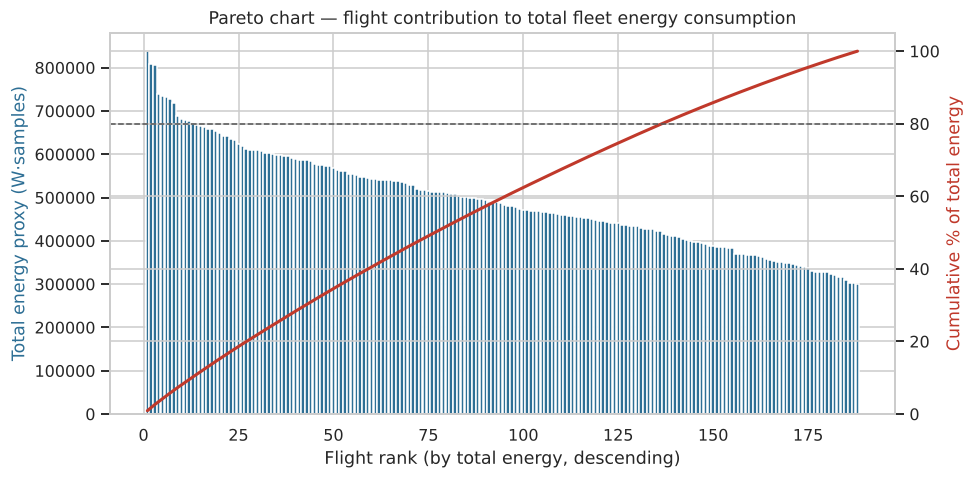

In [ ]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.bar(range(1, len(q6)+1), q6["total_energy"], color="#2E6F95", width=0.9)
ax1.set_xlabel("Flight rank (by total energy, descending)")
ax1.set_ylabel("Total energy proxy (W·samples)", color="#2E6F95")

ax2 = ax1.twinx()
ax2.plot(range(1, len(q6)+1), q6["cumulative_pct"], color="#C0392B", lw=2)
ax2.axhline(80, color="#555", ls="--", lw=1)
ax2.set_ylabel("Cumulative % of total energy", color="#C0392B")
ax2.set_ylim(0, 105)

ax1.set_title("Pareto chart — flight contribution to total fleet energy consumption")
plt.tight_layout()
fig.savefig("figs/fig_a6_pareto.pdf")
plt.show()


**Insight:** It takes 137 of the 188 flights (72.9%) to reach 80% of total fleet energy, and the top 20% of flights (37) account for only 26.4%, far from a classic 80/20 pattern. Energy is spread fairly evenly across the fleet rather than concentrated in a few outlier flights, so prioritisation should weight regime-level effects (see Analysis 3, where cruise duration is the dominant lever) rather than a short list of "worst offenders". The energy proxy sums power over samples, so it also reflects how long each flight is.

### Analysis 7 — Is a "Power-Hungry" Flight Power-Hungry in Every Regime? (DENSE_RANK + rank correlation)
**Serves:** RQ3
**Objective:** Check whether a flight that ranks high in power draw during one regime stays high in the others. Payload is constant per flight and is the biggest driver of power, so raw ranks are expected to agree across regimes simply because of payload. The query therefore ranks twice: on raw average power, and on power **relative to flights with the same payload** (`AVG() OVER (PARTITION BY regime, payload)`), then compares the two with Spearman correlations.

In [ ]:
q7 = con.execute('''
    WITH flight_regime AS (
        SELECT flight, regime, ANY_VALUE(payload) AS payload, AVG(power) AS avg_power
        FROM flight_telemetry GROUP BY flight, regime
    ),
    adjusted AS (
        SELECT *, avg_power - AVG(avg_power) OVER (PARTITION BY regime, payload) AS power_vs_peers
        FROM flight_regime
    ),
    ranked AS (
        SELECT flight, regime,
               DENSE_RANK() OVER (PARTITION BY regime ORDER BY avg_power DESC)       AS rank_raw,
               DENSE_RANK() OVER (PARTITION BY regime ORDER BY power_vs_peers DESC)  AS rank_adj
        FROM adjusted
    )
    SELECT flight,
        MAX(CASE WHEN regime='takeoff' THEN rank_raw END) AS raw_takeoff,
        MAX(CASE WHEN regime='cruise'  THEN rank_raw END) AS raw_cruise,
        MAX(CASE WHEN regime='landing' THEN rank_raw END) AS raw_landing,
        MAX(CASE WHEN regime='takeoff' THEN rank_adj END) AS adj_takeoff,
        MAX(CASE WHEN regime='cruise'  THEN rank_adj END) AS adj_cruise,
        MAX(CASE WHEN regime='landing' THEN rank_adj END) AS adj_landing
    FROM ranked GROUP BY flight
''').df()

pairs = [("takeoff", "cruise"), ("cruise", "landing"), ("takeoff", "landing")]
rho = pd.DataFrame({
    "raw ranks": [q7[f"raw_{a}"].corr(q7[f"raw_{b}"], method="spearman") for a, b in pairs],
    "ranks within payload group": [q7[f"adj_{a}"].corr(q7[f"adj_{b}"], method="spearman") for a, b in pairs],
}, index=[f"{a} vs {b}" for a, b in pairs]).round(2)
print("Spearman correlation of flight ranks between regimes:"); display(rho)

Spearman correlation of flight ranks between regimes:


,raw ranks,ranks within payload group
takeoff vs cruise,0.87,0.50
cruise vs landing,0.86,0.22
takeoff vs landing,0.83,0.26


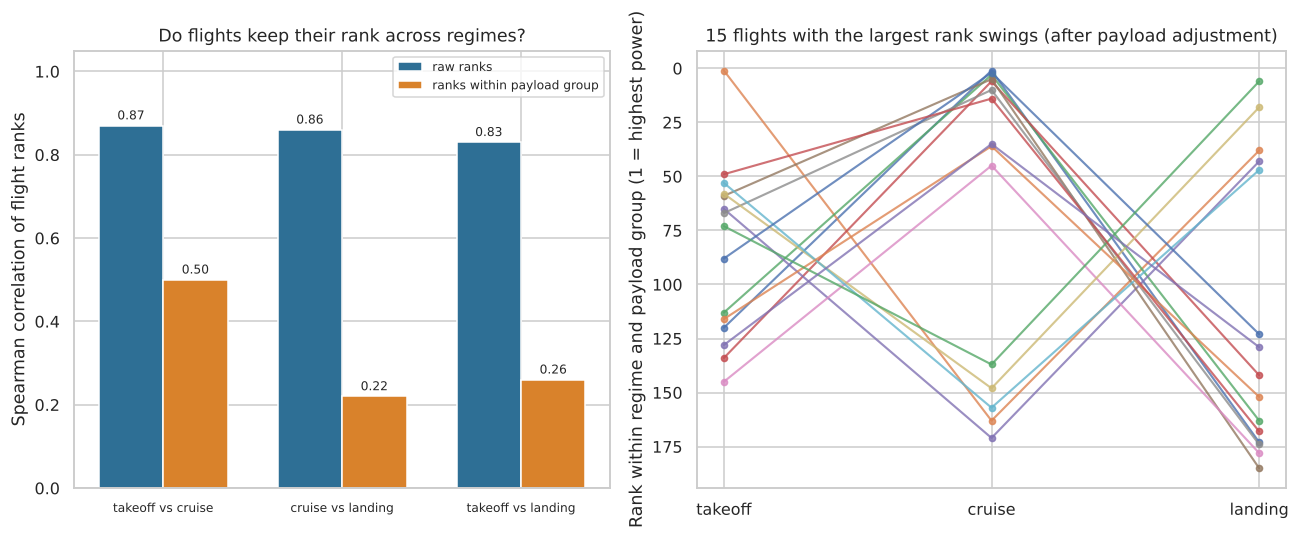

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})

x = np.arange(len(rho)); w = 0.36
axes[0].bar(x - w/2, rho["raw ranks"], w, color="#2E6F95", label="raw ranks")
axes[0].bar(x + w/2, rho["ranks within payload group"], w, color="#D9822B", label="ranks within payload group")
for xi, (a, b) in zip(x, zip(rho["raw ranks"], rho["ranks within payload group"])):
    axes[0].text(xi - w/2, a + 0.015, f"{a:.2f}", ha="center", fontsize=8)
    axes[0].text(xi + w/2, b + 0.015, f"{b:.2f}", ha="center", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(rho.index, fontsize=8)
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("Spearman correlation of flight ranks")
axes[0].set_title("Do flights keep their rank across regimes?")
axes[0].legend(fontsize=8, loc="upper right")

q7["swing"] = ((q7.adj_takeoff - q7.adj_cruise).abs() + (q7.adj_cruise - q7.adj_landing).abs())
for _, row in q7.sort_values("swing", ascending=False).head(15).iterrows():
    axes[1].plot(order, [row.adj_takeoff, row.adj_cruise, row.adj_landing], marker="o", ms=4, lw=1.4, alpha=0.8)
axes[1].invert_yaxis()
axes[1].set_ylabel("Rank within regime and payload group (1 = highest power)")
axes[1].set_title("15 flights with the largest rank swings (after payload adjustment)")
plt.tight_layout()
fig.savefig("figs/fig_a7_bump_rank.pdf")
plt.show()

**Insight:** On raw average power, flights keep their rank across regimes: Spearman 0.83-0.87 for every pair. That agreement is mostly payload, which is fixed per flight and moves power by about 100 W. Once each flight is ranked only against flights with the same payload, agreement drops to 0.50 (takeoff vs cruise), 0.26 (takeoff vs landing) and 0.22 (cruise vs landing). Heavy flights are power-hungry everywhere, but *beyond* payload, being unusually power-hungry in one regime says little about the others, especially landing. That favours payload-aware, per-regime monitoring over one fleet-wide watch-list. The bump chart shows the 15 largest swings to illustrate the spread; it is not a typical flight.

### Analysis 8 — Anomalous Power Readings (Z-score against comparable flights)
**Serves:** RQ4 (core)
**Objective:** Flag samples whose power deviates abnormally from what is expected **for the same conditions**. A Z-score against the whole regime is biased: payload shifts power by ~100 W, so heavy-payload samples look "high" and no-payload samples look "low" even when nothing is wrong. The expected value here is therefore the mean and std of samples in the same **regime x payload x speed** group (45 groups). The old regime-only Z is kept in the output for comparison.

In [ ]:
q8 = con.execute('''
    WITH cond_stats AS (
        SELECT regime, payload, speed, AVG(power) AS mean_power, STDDEV(power) AS std_power
        FROM flight_telemetry GROUP BY regime, payload, speed
    ),
    regime_stats AS (
        SELECT regime, AVG(power) AS mean_power, STDDEV(power) AS std_power
        FROM flight_telemetry GROUP BY regime
    ),
    zscored AS (
        SELECT t.flight, t.regime, t.sample_seq, t.power, t.payload, t.speed, t.wind_speed,
               (t.power - c.mean_power) / NULLIF(c.std_power, 0) AS z_score,
               (t.power - r.mean_power) / NULLIF(r.std_power, 0) AS z_regime_only
        FROM flight_telemetry t
        JOIN cond_stats   c ON c.regime = t.regime AND c.payload = t.payload AND c.speed = t.speed
        JOIN regime_stats r ON r.regime = t.regime
    )
    SELECT *,
        CASE WHEN ABS(z_score) >= 3 THEN 'Severe outlier (|Z|>=3)'
             WHEN ABS(z_score) >= 2 THEN 'Mild outlier (2<=|Z|<3)'
             ELSE 'Normal' END AS anomaly_flag
    FROM zscored
''').df()

print(q8["anomaly_flag"].value_counts(), "\n")
print("Outlier share by regime (%):")
print((q8[q8.anomaly_flag != "Normal"].groupby("regime").size() / q8.groupby("regime").size() * 100).round(2).loc[order], "\n")

flag = pd.DataFrame({"regime-only Z": q8.z_regime_only.abs() >= 2, "condition-adjusted Z": q8.z_score.abs() >= 2})
rate_by_payload = (flag.groupby(q8["payload"]).mean() * 100).round(2)
print("Share of samples flagged (|Z|>=2) by payload, old vs adjusted definition (%):"); display(rate_by_payload)

flags_per_flight = q8[q8.z_score.abs() >= 2].groupby("flight").size().sort_values(ascending=False)
print(f"Flights with at least one flagged sample: {flags_per_flight.shape[0]} / 188")
print(f"Share of all flags coming from the 10 flights with most flags: {100 * flags_per_flight.head(10).sum() / flags_per_flight.sum():.1f}%")
print(f"Share of all flags coming from the 20% of flights with most flags ({int(0.2 * 188)} flights): {100 * flags_per_flight.head(int(0.2 * 188)).sum() / flags_per_flight.sum():.1f}%")

anomaly_flag
Normal                     168620
Mild outlier (2<=|Z|<3)      6455
Severe outlier (|Z|>=3)      2389
Name: count, dtype: int64 

Outlier share by regime (%):
regime
takeoff    5.53
cruise     4.99
landing    4.63
dtype: float64 

Share of samples flagged (|Z|>=2) by payload, old vs adjusted definition (%):


,regime-only Z,condition-adjusted Z
payload,,
0.0,4.74,5.00
250.0,3.46,5.10
500.0,5.93,4.85


Flights with at least one flagged sample: 188 / 188
Share of all flags coming from the 10 flights with most flags: 16.9%
Share of all flags coming from the 20% of flights with most flags (37 flights): 42.4%


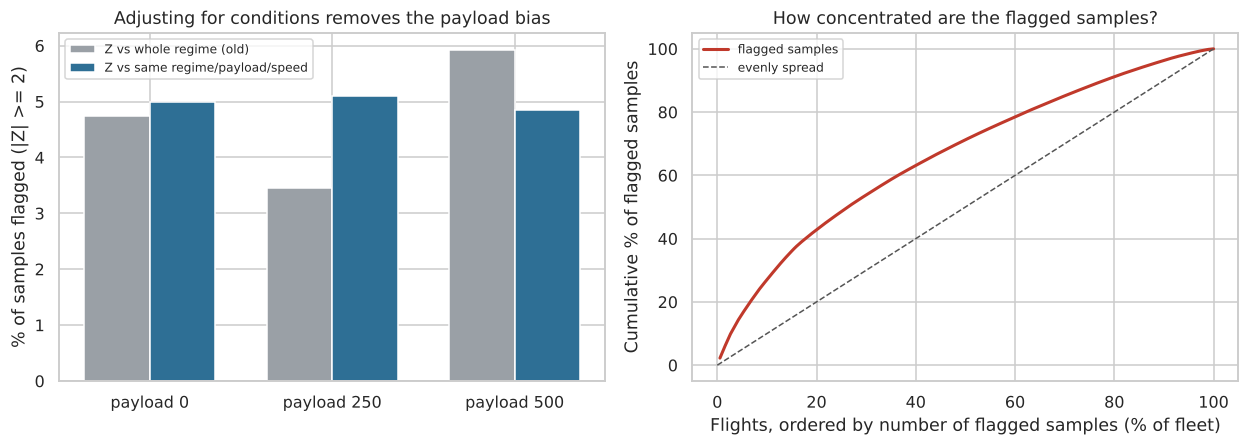

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

x = np.arange(len(rate_by_payload)); w = 0.36
axes[0].bar(x - w/2, rate_by_payload["regime-only Z"], w, color="#9AA0A6", label="Z vs whole regime (old)")
axes[0].bar(x + w/2, rate_by_payload["condition-adjusted Z"], w, color="#2E6F95", label="Z vs same regime/payload/speed")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"payload {int(p)}" for p in rate_by_payload.index])
axes[0].set_ylabel("% of samples flagged (|Z| >= 2)")
axes[0].set_title("Adjusting for conditions removes the payload bias")
axes[0].legend(fontsize=8)

cum = flags_per_flight.cumsum() / flags_per_flight.sum() * 100
share_flights = np.arange(1, len(cum) + 1) / 188 * 100
axes[1].plot(share_flights, cum.values, color="#C0392B", lw=2, label="flagged samples")
axes[1].plot([0, 100], [0, 100], color="#555", ls="--", lw=1, label="evenly spread")
axes[1].set_xlabel("Flights, ordered by number of flagged samples (% of fleet)")
axes[1].set_ylabel("Cumulative % of flagged samples")
axes[1].set_title("How concentrated are the flagged samples?")
axes[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig("figs/fig_a8_outliers.pdf")
plt.show()

**Insight:** Judged against comparable flights (same regime, payload and speed), samples are flagged at an even rate across payloads: 5.00% (payload 0), 5.10% (250) and 4.85% (500). The old regime-wide Z-score flagged anywhere from 3.46% to 5.93% depending on payload, so it partly measured payload rather than anomalies. With the adjusted definition, 6,455 samples are mild outliers and 2,389 are severe. Flagged samples are not confined to a few flights (all 188 flights contain some), but they are uneven: the 10 flights with the most flags (5% of the fleet) hold 16.9% of all flags and the top 20% of flights hold 42.4%, roughly twice their share. A watch-list of the most affected flights is reasonable, but it would still miss more than half of the flagged samples. The rate is similar across regimes (takeoff 5.53%, cruise 4.99%, landing 4.63%), so the same threshold can be used in every regime, and flagged points are best reviewed individually for sensor faults or unusual manoeuvres.

### Analysis 9 — Safe-Band Share by Regime
**Serves:** RQ4
**Objective:** Report the share of samples inside the statistically "safe" band (|Z| < 2, using the same condition-adjusted Z as Analysis 8) in takeoff, cruise and landing. Note that a 2-sigma rule keeps roughly 95% of samples by construction, so the useful signal is the *difference between regimes*, not the 95% itself.

In [ ]:
con.register("q8_flags", q8[["flight", "regime", "z_score"]])
q9 = con.execute('''
    SELECT regime,
           SUM(CASE WHEN ABS(z_score) < 2 THEN 1 ELSE 0 END)           AS safe_samples,
           COUNT(*)                                                    AS total_samples,
           100.0 * SUM(CASE WHEN ABS(z_score) < 2 THEN 1 ELSE 0 END) / COUNT(*) AS safe_rate_pct
    FROM q8_flags GROUP BY regime
''').df()
q9 = q9.set_index("regime").loc[order].reset_index()
q9.round(2)

,regime,safe_samples,total_samples,safe_rate_pct
0,takeoff,29190.0,30900,94.47
1,cruise,91083.0,95871,95.01
2,landing,48347.0,50693,95.37


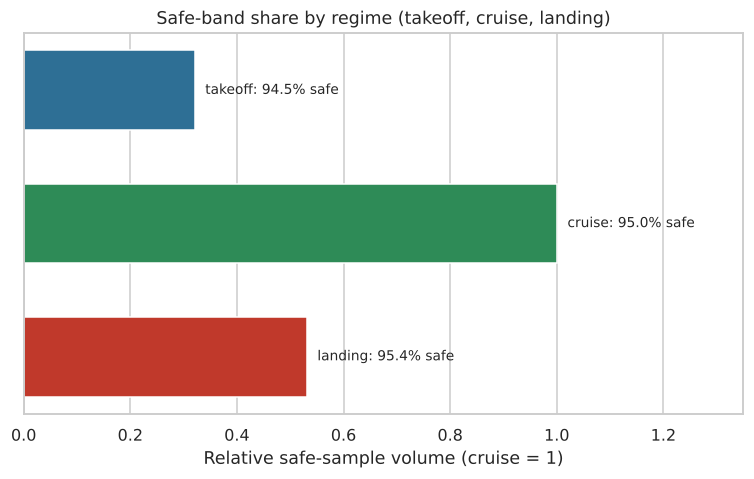

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
widths = q9["safe_samples"] / q9["safe_samples"].max()
for i, (reg, w_, rate) in enumerate(zip(q9["regime"], widths, q9["safe_rate_pct"])):
    ax.barh(i, w_, height=0.6, color=["#2E6F95", "#2E8B57", "#C0392B"][i])
    ax.text(w_ + 0.02, i, f"{reg}: {rate:.1f}% safe", va="center", fontsize=9)
ax.set_yticks([]); ax.set_xlim(0, 1.35); ax.invert_yaxis()
ax.set_xlabel("Relative safe-sample volume (cruise = 1)")
ax.set_title("Safe-band share by regime (takeoff, cruise, landing)")
plt.tight_layout()
fig.savefig("figs/fig_a9_funnel.pdf")
plt.show()

**Insight:** A 2-sigma rule keeps about 95% of samples by construction, and that is what we see: 94.5% in takeoff, 95.0% in cruise and 95.4% in landing. The gap between regimes is under one percentage point, so no phase is meaningfully less stable than another. In absolute volume, safe samples are dominated by cruise simply because it is the longest phase, so monitoring effort covers the most data in cruise even though the risk per sample is similar across phases.

### Analysis 10 — Headwind and Power, with Sample Sizes (Conditional Aggregation)
**Serves:** RQ3
**Objective:** Quantify how headwind relates to power draw, using conditional aggregation to compare four wind bands in one query. Two safeguards are added: (1) every cell reports its number of samples and flights, and (2) power is expressed **relative to the average of the same regime and payload** (window `AVG() OVER (PARTITION BY regime, payload)`), because wind bands contain different payload mixes and payload alone moves power by ~100 W.

In [ ]:
q10_long = con.execute('''
    WITH env AS (
        SELECT regime, flight, power,
               power - AVG(power) OVER (PARTITION BY regime, payload) AS power_vs_payload_mean,
               CASE WHEN headwind < -2 THEN 'tailwind'
                    WHEN headwind <  2 THEN 'neutral'
                    WHEN headwind <  6 THEN 'moderate'
                    ELSE 'strong' END AS headwind_band
        FROM flight_telemetry
    )
    SELECT regime, headwind_band,
           COUNT(*) AS n_samples, COUNT(DISTINCT flight) AS n_flights,
           ROUND(AVG(power), 1) AS avg_power_raw,
           ROUND(AVG(power_vs_payload_mean), 1) AS avg_power_payload_adjusted
    FROM env GROUP BY regime, headwind_band
''').df()

q10 = con.execute('''
    WITH env AS (
        SELECT regime, power,
               power - AVG(power) OVER (PARTITION BY regime, payload) AS adj,
               CASE WHEN headwind < -2 THEN 'tailwind'
                    WHEN headwind <  2 THEN 'neutral'
                    WHEN headwind <  6 THEN 'moderate'
                    ELSE 'strong' END AS band
        FROM flight_telemetry
    )
    SELECT regime,
        ROUND(AVG(CASE WHEN band = 'tailwind'  THEN adj END), 1) AS tailwind,
        ROUND(AVG(CASE WHEN band = 'neutral'   THEN adj END), 1) AS neutral,
        ROUND(AVG(CASE WHEN band = 'moderate'  THEN adj END), 1) AS moderate_headwind,
        ROUND(AVG(CASE WHEN band = 'strong'    THEN adj END), 1) AS strong_headwind
    FROM env GROUP BY regime
''').df().set_index("regime").loc[order]

print("Payload-adjusted power vs same regime & payload average (W):"); display(q10)
cols = ["tailwind", "neutral", "moderate", "strong"]
print("Flights per cell:")
display(q10_long.pivot(index="regime", columns="headwind_band", values="n_flights").reindex(index=order, columns=cols))
print("Samples per cell:")
display(q10_long.pivot(index="regime", columns="headwind_band", values="n_samples").reindex(index=order, columns=cols))
print("Raw average power per cell (W), before payload adjustment:")
display(q10_long.pivot(index="regime", columns="headwind_band", values="avg_power_raw").reindex(index=order, columns=cols))

Payload-adjusted power vs same regime & payload average (W):


,tailwind,neutral,moderate_headwind,strong_headwind
regime,,,,
takeoff,2.1,-2.9,0.7,15.0
cruise,-13.4,10.2,4.4,8.5
landing,8.8,-1.3,9.1,-44.7


Flights per cell:


headwind_band,tailwind,neutral,moderate,strong
regime,,,,
takeoff,121,181,113,18
cruise,185,188,188,162
landing,151,188,160,105


Samples per cell:


headwind_band,tailwind,neutral,moderate,strong
regime,,,,
takeoff,9003,13453,7461,983
cruise,34840,21496,21474,18061
landing,8552,29441,9858,2842


Raw average power per cell (W), before payload adjustment:


headwind_band,tailwind,neutral,moderate,strong
regime,,,,
takeoff,611.9,595.6,595.7,598.7
cruise,503.1,525.5,518.1,521.9
landing,503.7,494.8,497.1,440.3


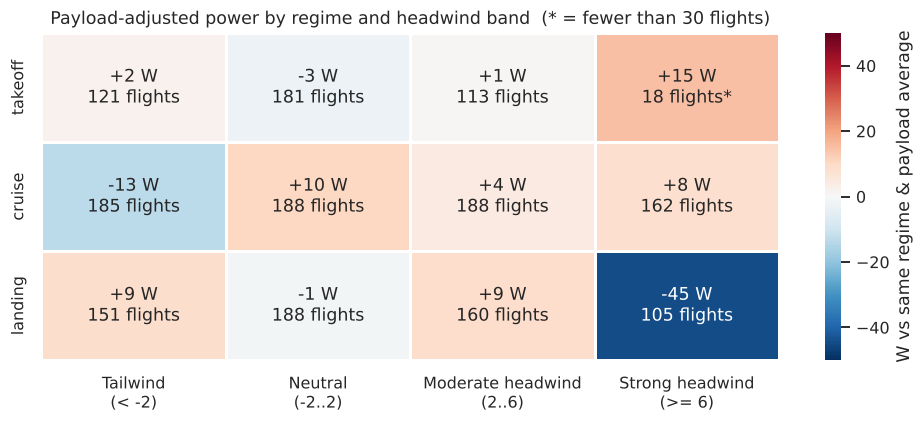

In [ ]:
bands = ["tailwind", "neutral", "moderate", "strong"]
adj = q10_long.pivot(index="regime", columns="headwind_band", values="avg_power_payload_adjusted").reindex(index=order, columns=bands)
nfl = q10_long.pivot(index="regime", columns="headwind_band", values="n_flights").reindex(index=order, columns=bands)

annot = adj.copy().astype(object)
for r in adj.index:
    for b in bands:
        star = "*" if nfl.loc[r, b] < 30 else ""
        annot.loc[r, b] = f"{adj.loc[r, b]:+.0f} W\n{int(nfl.loc[r, b])} flights{star}"

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(adj, annot=annot, fmt="", cmap="RdBu_r", center=0, vmin=-50, vmax=50, linewidths=0.8, ax=ax,
            cbar_kws={"label": "W vs same regime & payload average"})
ax.set_xticklabels(["Tailwind\n(< -2)", "Neutral\n(-2..2)", "Moderate headwind\n(2..6)", "Strong headwind\n(>= 6)"], rotation=0)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Payload-adjusted power by regime and headwind band  (* = fewer than 30 flights)")
plt.tight_layout()
fig.savefig("figs/fig_a10_wind_effect.pdf")
plt.show()

**Insight:** Wind matters, but not as a simple "more headwind = more power" rule, and each cell is only as reliable as the number of flights behind it. After adjusting for payload: in cruise, tailwind is the lowest (-13.4 W) while neutral and headwind bands sit +4 to +10 W above average. In landing, strong headwind is clearly the cheapest condition (-44.7 W, 105 flights, 2,842 samples); the effect largely survives the payload adjustment (raw 440 W vs 495-504 W in the other bands). Takeoff looks flat (-3 to +2 W) except strong headwind (+15 W), which rests on only 18 flights and 983 samples and should not be trusted. A plausible explanation for the landing result is that a headwind lowers the ground speed needed during deceleration; this data does not test it. The wind window should be set per regime, and the landing result is the first one worth validating.

## Summary — RQ ↔ Analysis Mapping

| RQ | Analyses |
|---|---|
| RQ1 — Trend & Cycles | 1, 2, 3 |
| RQ2 — Behavioral Segmentation | 4, 5 |
| RQ3 — Contribution & Optimization | 6, 7, 10 |
| RQ4 — Anomaly Detection | 8, 9 |
